In [2]:
import sys
sys.path.append("/home/macbuse/miniconda3/lib/python3.11/site-packages")

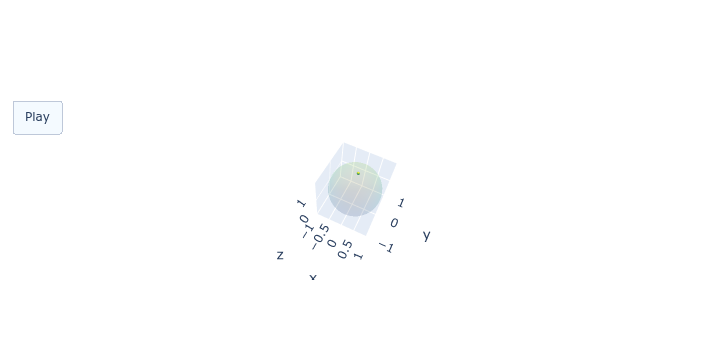

In [4]:
import numpy as np
import plotly.graph_objects as go

# 1. Generate the data for a sphere
def get_sphere(radius, center, resolution=50):
    u = np.linspace(0, 2 * np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)
    x = radius * np.outer(np.cos(u), np.sin(v)) + center[0]
    y = radius * np.outer(np.sin(u), np.sin(v)) + center[1]
    z = radius * np.outer(np.ones(np.size(u)), np.cos(v)) + center[2]
    return x, y, z

# 2. Setup the "Ideal Point" (where the horosphere is tangent to the boundary)
p = np.array([0, 0, 1])  # Tangent at the North Pole

# 3. Create frames for the animation
# 'd' is the Euclidean distance from the origin to the "bottom" of the horosphere
distances = np.linspace(0.9, -0.9, 40) 
frames = []

for d in distances:
    r_eucl = (1 - d) / 2
    c_eucl = p * (1 - r_eucl)
    x, y, z = get_sphere(r_eucl, c_eucl)
    S1 = go.Surface(x=x, y=y, z=z, 
               colorscale='Viridis', showscale=False)
    frames.append(go.Frame(data=[S1]))

# 4. Create the initial plot (the boundary sphere + first horosphere frame)
x_bound, y_bound, z_bound = get_sphere(1, [0, 0, 0])
fig = go.Figure(
    data=[
        # The Boundary at Infinity (Unit Sphere)
        go.Surface(x=x_bound, y=y_bound, z=z_bound,
                   opacity=0.1, showscale=False, hoverinfo='none'),
        # The Initial Horosphere
        frames[0].data[0]
    ],
    layout=go.Layout(
        scene=dict(xaxis=dict(range=[-1,1]), yaxis=dict(range=[-1,1]), zaxis=dict(range=[-1,1]), aspectmode='cube'),
        updatemenus=[dict(type="buttons", 
                    buttons=[dict(label="Play", 
                    method="animate", args=[None])])]
    ),
    frames=frames
)

fig.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt

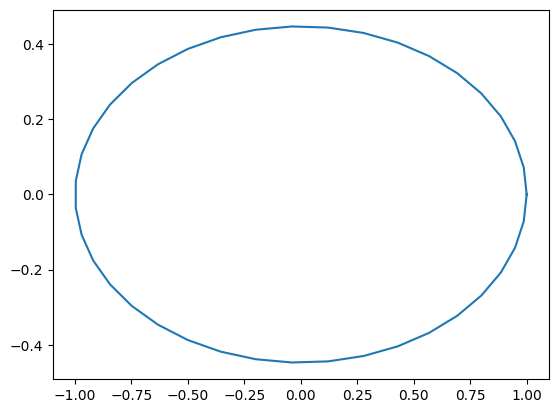

In [12]:
T =  np.linspace(0, 2*np.pi,40)
Z = np.exp(1J*T)


fig, ax = plt.subplots()
ax.plot(Z.real,Z.imag/np.sqrt(5));


In [39]:
A  = [1,-.5,-.5,2]
A = np.array(A).reshape(2,2)
A

array([[ 1. , -0.5],
       [-0.5,  2. ]])

In [52]:
ee, bb = np.linalg.eig(A)
bb

array([[-0.92387953,  0.38268343],
       [-0.38268343, -0.92387953]])

In [53]:
([2,1]@A)@[2,1]

np.float64(4.0)

In [54]:
bb.T@bb

array([[1., 0.],
       [0., 1.]])

/tmp/ipykernel_3695/2367565854.py:17: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



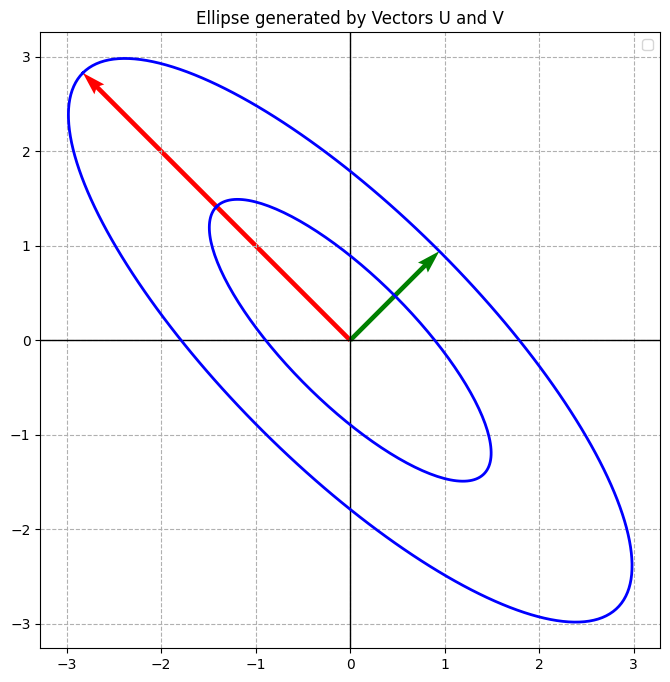

In [98]:
A  = [1,.5,.5,1]

#A = [2,0,0,1]

A = np.array(A).reshape(2,2)

ee, bb = np.linalg.eig(A)


plt.figure(figsize=(8, 8))

    
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.grid(True, linestyle='--')
plt.axis('equal') # Crucial to ensure the ellipse isn't distorted
plt.legend()
plt.title("Ellipse generated by Vectors U and V")

def plot_ellipse(u, v, origin=[0, 0], n_points=200):

    t = np.linspace(0, 2*np.pi, n_points)
    
    # 2. Calculate the points: r(t) = cos(t)*u + sin(t)*v
    # Using np.outer for broadcasting across the vectors
    ellipse_points = np.outer(np.cos(t), u) + np.outer(np.sin(t), v)
    
    # Shift by origin
    x = ellipse_points[:, 0] + origin[0]
    y = ellipse_points[:, 1] + origin[1]

    plt.plot(x, y, label='Ellipse', color='blue', linewidth=2)


   

# Example: Define two vectors


for r in [1,2]:
    U,V = (r*bb).T
    U /= ee[0]
    V /= ee[1]
    
    plot_ellipse(V,U)

u,v = V,U
origin = [0,0]
    # Plot the basis vectors U and V
plt.quiver(*origin, u[0], u[1], color='red', angles='xy', 
               scale_units='xy', scale=1, label='Vector U')
plt.quiver(*origin, v[0], v[1], color='green', angles='xy', 
               scale_units='xy', scale=1, label='Vector V')


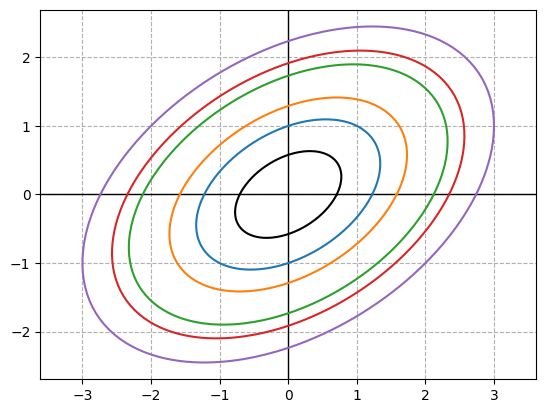

In [209]:

T =  np.linspace(0, 2*np.pi,200)
Z = np.exp(1J*T)

X, Y = Z.real,Z.imag

#Z /= np.sqrt((X**2 - X*Y + 3*Y**2))
Z /= np.sqrt((2*X**2 - 2*X*Y + 3*Y**2))

fig, ax = plt.subplots()
ax.axis('equal') 
ax.grid(True, linestyle='--')
ax.axhline(0, color='black', lw=1)
ax.axvline(0, color='black', lw=1)

for r in [3,5,9,11,15]:
    W = np.sqrt(r)*Z
    ax.plot(W.real, W.imag);
W = Z
ax.plot(W.real, W.imag,'k');

ff = 4*1.04
#ax.plot([0,ff*y],[0,ff*x],'k');

In [148]:
L = list(zip(abs(W),W/abs(W)))
L.sort()
L[0],L[-1]

((np.float64(0.5663186964099746),
  np.complex128(-0.22691610896159004+0.9739143080855378j)),
 (np.float64(1.064781322266625),
  np.complex128(-0.9720928355242571-0.23459650279236868j)))

In [199]:
A = np.array([[1,-.5],[-.5,3]])
vv, bb = np.linalg.eig(A)
np.sqrt(1/vv)

array([1.06481479, 0.56631697])

In [177]:
(.5663*1.0645)**2

0.3633996082543226

In [175]:
1/2.75

0.36363636363636365

In [157]:
.5666*1.064

0.6028624

In [159]:
np.linalg.det(A)

np.float64(2.75)

In [172]:
vv[0]*vv[1]

np.float64(1.6583123951777)

In [178]:
(L[0][0]*L[-1][0])**2

np.float64(0.36361571791862446)

In [186]:
x, y = -bb[1]

In [206]:
1/vv

array([1.13383054, 0.32071491])

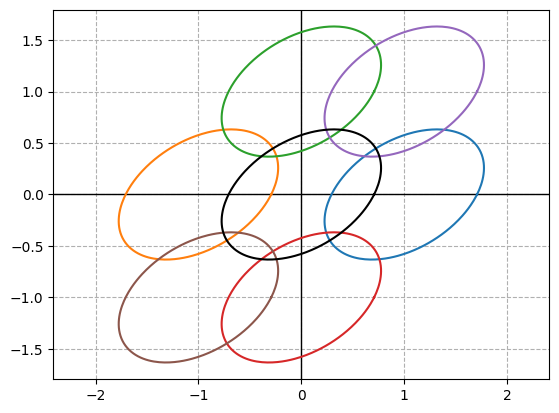

In [226]:
T =  np.linspace(0, 2*np.pi,200)
Z = np.exp(1J*T)

X, Y = Z.real,Z.imag


Z /= np.sqrt((2*X**2 - 2*X*Y + 3*Y**2))

fig, ax = plt.subplots()
ax.axis('equal') 
ax.grid(True, linestyle='--')
ax.axhline(0, color='black', lw=1)
ax.axvline(0, color='black', lw=1)

ff = np.sqrt(1)
for z in [1,-1,1J,-1J,1+1J,-(1+1J)]:
    W = ff*Z + z
    ax.plot(W.real, W.imag);


ax.plot(ff*Z.real, ff*Z.imag,'k');



